# 阶段 3：增益模型

手写的方法在 `src/meta_learners.py`：普通响应模型（对照）、S-learner、T-learner、X-learner、类别转换法。

1. **模拟数据检验**：造一份已知真实增益的数据，看各方法能否找回真实增益（X-learner 在 scikit-uplift 里没有现成实现，用这种方式验证）。
2. **与 scikit-uplift 对比**：S-learner、T-learner、类别转换法用相同的基础模型，预测结果应该完全一致。
3. **真实数据**：在训练集上训练，在验证集上挑模型（按 Qini 系数），最后在测试集上统一评估一次。

## 3.1 模拟数据检验：已知真实增益时，各方法能找回多少？

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DATA_PROCESSED, RESULTS, SEED
from src.features import FEATURE_DESC
from src.meta_learners import (ClassTransformation, ResponseModel, SLearner, TLearner, XLearner, lgbm_classifier,
                               lgbm_regressor, logistic, ridge)
from src.plotting import INK_SECONDARY, SERIES, setup_matplotlib
from src.uplift_eval import qini_auc, uplift_at_k, uplift_auc

setup_matplotlib()

# 模拟：不发短信时的购买概率 p0 由 x1 决定；短信的真实增益由 x2、x3 决定（有正有负），x4、x5 是无关特征
rng = np.random.default_rng(SEED)
n = 60_000
Xs = rng.normal(size=(n, 5))
p0 = 1 / (1 + np.exp(-(0.3 + 0.8 * Xs[:, 0])))
true_uplift = np.clip(0.04 + 0.06 * (Xs[:, 1] > 0) - 0.03 * Xs[:, 2], -0.2, 0.3)
p1 = np.clip(p0 + true_uplift, 0, 1)
true_uplift = p1 - p0
ts = rng.integers(0, 2, n)
ys = (rng.random(n) < np.where(ts == 1, p1, p0)).astype(int)
tr_s, te_s = slice(0, 40_000), slice(40_000, n)

sim_models = {
    "S-learner（LightGBM）": SLearner(lgbm_classifier()),
    "T-learner（LightGBM）": TLearner(lgbm_classifier()),
    "X-learner（LightGBM）": XLearner(lgbm_classifier(), lgbm_regressor()),
    "类别转换法（LightGBM）": ClassTransformation(lgbm_classifier()),
}
sim_rows = {}
for name, m in sim_models.items():
    pred = m.fit(Xs[tr_s], ys[tr_s], ts[tr_s]).predict_uplift(Xs[te_s])
    sim_rows[name] = {"与真实增益的相关系数": float(np.corrcoef(pred, true_uplift[te_s])[0, 1]),
                      "预测增益的标准差": float(pred.std()), "真实增益的标准差": float(true_uplift[te_s].std()),
                      "Qini 系数（用观测结果算）": qini_auc(ys[te_s], pred, ts[te_s])}
sim_rows["真实增益（理论上限）"] = {"与真实增益的相关系数": 1.0, "预测增益的标准差": float(true_uplift[te_s].std()),
                             "真实增益的标准差": float(true_uplift[te_s].std()),
                             "Qini 系数（用观测结果算）": qini_auc(ys[te_s], true_uplift[te_s], ts[te_s])}
sim_table = pd.DataFrame(sim_rows).T
sim_table.round(4)

,与真实增益的相关系数,预测增益的标准差,真实增益的标准差,Qini 系数（用观测结果算）
S-learner（LightGBM）,0.7808,0.0518,0.0424,0.0206
T-learner（LightGBM）,0.4369,0.1098,0.0424,0.0113
X-learner（LightGBM）,0.5341,0.0893,0.0424,0.0140
类别转换法（LightGBM）,0.3704,0.1136,0.0424,0.0066
真实增益（理论上限）,1.0000,0.0424,0.0424,0.0287


## 3.2 与 scikit-uplift 对比（基础模型都用逻辑回归）

In [2]:
from sklift.models import ClassTransformation as SkCT
from sklift.models import SoloModel, TwoModels

data = pd.read_parquet(DATA_PROCESSED / "features.parquet")
split = pd.read_csv(DATA_PROCESSED / "split.csv", index_col=0)["split"].reindex(data.index)
FEATURES = list(FEATURE_DESC)
parts = {s: data[split == s] for s in ["train", "valid", "test"]}
X = {s: p[FEATURES].to_numpy(float) for s, p in parts.items()}
y = {s: p["target"].to_numpy() for s, p in parts.items()}
t = {s: p["treatment_flg"].to_numpy() for s, p in parts.items()}

check = {
    "S-learner vs SoloModel": (SLearner(logistic()), SoloModel(estimator=logistic(), method="dummy")),
    "T-learner vs TwoModels": (TLearner(logistic()), TwoModels(estimator_trmnt=logistic(), estimator_ctrl=logistic(), method="vanilla")),
    "类别转换法 vs ClassTransformation": (ClassTransformation(logistic()), SkCT(estimator=logistic())),
}
lib_check = {}
for name, (mine, ref) in check.items():
    a = mine.fit(X["train"], y["train"], t["train"]).predict_uplift(X["valid"])
    b = ref.fit(X["train"], y["train"], t["train"]).predict(X["valid"])
    lib_check[name] = float(np.max(np.abs(a - b)))
pd.Series(lib_check).to_frame("验证集上预测值的最大差异")

,验证集上预测值的最大差异
S-learner vs SoloModel,0.0
T-learner vs TwoModels,0.0
类别转换法 vs ClassTransformation,0.0


## 3.3 真实数据：训练集训练，验证集评估

候选模型（共 12 个）：
- 普通响应模型（LightGBM）：只预测“会不会买”，作为对照；
- S-learner、T-learner、类别转换法：分别用逻辑回归和 LightGBM 做基础模型；
- X-learner：逻辑回归 + Ridge 回归，以及 LightGBM 分类 + LightGBM 回归；
- 再加 3 个“保守版” LightGBM（叶子更少、每个叶子的样本更多），看看降低复杂度会不会更好。

评估指标（都在验证集上算）：Qini 系数（标准化 Qini 曲线下面积）、AUUC（标准化增益曲线下面积）、前 30% 增益（X5 比赛用的指标，在全体样本里取预测增益最高的 30%）。

In [3]:
conservative = dict(num_leaves=15, min_child_samples=300, n_estimators=200)
candidates = {
    "响应模型（LightGBM，对照）": ResponseModel(lgbm_classifier()),
    "S-learner（逻辑回归）": SLearner(logistic()),
    "S-learner（LightGBM）": SLearner(lgbm_classifier()),
    "T-learner（逻辑回归）": TLearner(logistic()),
    "T-learner（LightGBM）": TLearner(lgbm_classifier()),
    "T-learner（LightGBM 保守版）": TLearner(lgbm_classifier(**conservative)),
    "X-learner（逻辑回归 + Ridge）": XLearner(logistic(), ridge()),
    "X-learner（LightGBM）": XLearner(lgbm_classifier(), lgbm_regressor()),
    "X-learner（LightGBM 保守版）": XLearner(lgbm_classifier(**conservative), lgbm_regressor(**conservative)),
    "类别转换法（逻辑回归）": ClassTransformation(logistic()),
    "类别转换法（LightGBM）": ClassTransformation(lgbm_classifier()),
    "类别转换法（LightGBM 保守版）": ClassTransformation(lgbm_classifier(**conservative)),
}


def evaluate(yv, pred, tv):
    return {"Qini 系数": qini_auc(yv, pred, tv), "AUUC": uplift_auc(yv, pred, tv),
            "前30%增益": uplift_at_k(yv, pred, tv, k=0.3, strategy="overall")}


fitted, preds, valid_rows, fit_seconds = {}, {}, {}, {}
for name, m in candidates.items():
    start = time.time()
    fitted[name] = m.fit(X["train"], y["train"], t["train"])
    fit_seconds[name] = time.time() - start
    preds[name] = {s: fitted[name].predict_uplift(X[s]) for s in ["valid", "test"]}
    valid_rows[name] = evaluate(y["valid"], preds[name]["valid"], t["valid"])
valid_table = pd.DataFrame(valid_rows).T.sort_values("Qini 系数", ascending=False)
valid_table["训练用时（秒）"] = pd.Series(fit_seconds)
valid_table.round(4)

,Qini 系数,AUUC,前30%增益,训练用时（秒）
T-learner（逻辑回归）,0.0155,0.0244,0.0631,0.8876
X-learner（逻辑回归 + Ridge）,0.0147,0.0231,0.0589,1.6706
S-learner（LightGBM）,0.0147,0.0229,0.0596,1.9579
类别转换法（逻辑回归）,0.0146,0.0229,0.0617,1.1468
X-learner（LightGBM 保守版）,0.0145,0.0225,0.0626,3.9854
T-learner（LightGBM 保守版）,0.0142,0.0220,0.0562,1.2467
S-learner（逻辑回归）,0.0136,0.0208,0.0630,0.9129
类别转换法（LightGBM 保守版）,0.0128,0.0197,0.0567,1.2388
类别转换法（LightGBM）,0.0108,0.0168,0.0583,2.3332
T-learner（LightGBM）,0.0102,0.0159,0.0551,2.2293


## 3.4 选择最终模型

只看验证集，选 Qini 系数最高的增益模型（响应模型只作对照，不参与选择）。

In [4]:
uplift_only = valid_table.drop(index="响应模型（LightGBM，对照）")
FINAL = uplift_only.index[0]
print("验证集 Qini 系数最高：", FINAL)
uplift_only.head(5).round(4)

验证集 Qini 系数最高： T-learner（逻辑回归）


,Qini 系数,AUUC,前30%增益,训练用时（秒）
T-learner（逻辑回归）,0.0155,0.0244,0.0631,0.8876
X-learner（逻辑回归 + Ridge）,0.0147,0.0231,0.0589,1.6706
S-learner（LightGBM）,0.0147,0.0229,0.0596,1.9579
类别转换法（逻辑回归）,0.0146,0.0229,0.0617,1.1468
X-learner（LightGBM 保守版）,0.0145,0.0225,0.0626,3.9854


## 3.5 测试集：所有模型统一评估一次

模型已经在验证集上选好了，测试集的结果只用来报告，不再用来挑选。

In [5]:
test_rows = {name: evaluate(y["test"], preds[name]["test"], t["test"]) for name in candidates}
test_table = pd.DataFrame(test_rows).T.loc[valid_table.index]
compare = pd.concat({"验证集": valid_table[["Qini 系数", "AUUC", "前30%增益"]], "测试集": test_table}, axis=1)
compare.to_csv(RESULTS / "stage3_model_comparison.csv", encoding="utf-8-sig")
compare.round(4)

验证集                     测试集                
                        Qini 系数    AUUC  前30%增益 Qini 系数    AUUC  前30%增益
T-learner（逻辑回归）          0.0155  0.0244  0.0631  0.0129  0.0200  0.0657
X-learner（逻辑回归 + Ridge）  0.0147  0.0231  0.0589  0.0121  0.0188  0.0599
S-learner（LightGBM）      0.0147  0.0229  0.0596  0.0109  0.0171  0.0639
类别转换法（逻辑回归）              0.0146  0.0229  0.0617  0.0127  0.0197  0.0560
X-learner（LightGBM 保守版）  0.0145  0.0225  0.0626  0.0104  0.0161  0.0516
T-learner（LightGBM 保守版）  0.0142  0.0220  0.0562  0.0069  0.0109  0.0485
S-learner（逻辑回归）          0.0136  0.0208  0.0630  0.0061  0.0096  0.0440
类别转换法（LightGBM 保守版）      0.0128  0.0197  0.0567  0.0098  0.0150  0.0504
类别转换法（LightGBM）          0.0108  0.0168  0.0583  0.0091  0.0136  0.0546
T-learner（LightGBM）      0.0102  0.0159  0.0551  0.0048  0.0073  0.0444
X-learner（LightGBM）      0.0100  0.0155  0.0525  0.0062  0.0097  0.0512
响应模型（LightGBM，对照）       -0.0112 -0.0173  0.0135 -0.0052 -0.0081  0.0147

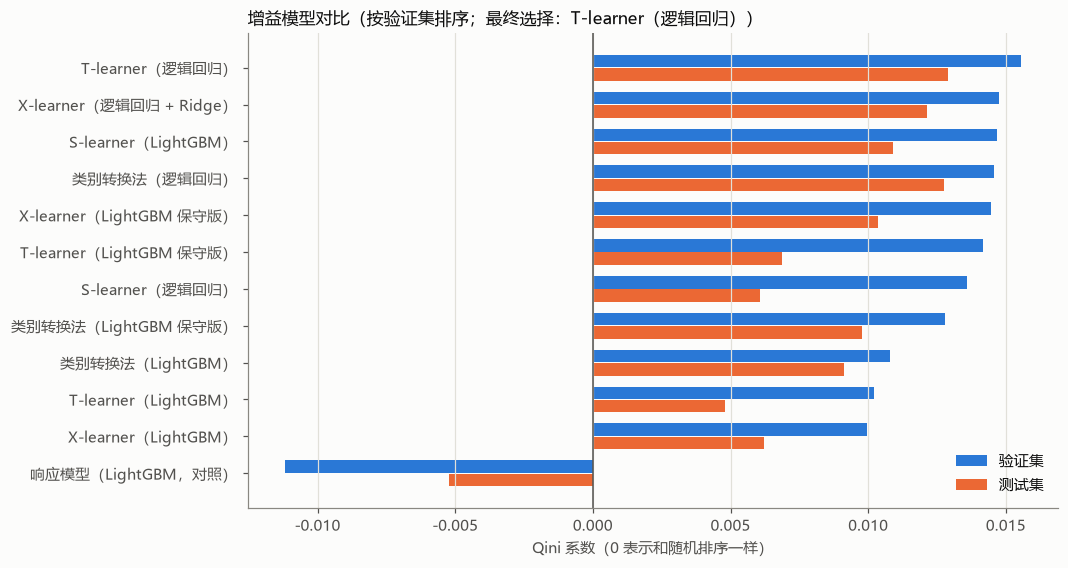

In [6]:
order = valid_table.index.tolist()
fig, ax = plt.subplots(figsize=(9.5, 5.6))
yy = np.arange(len(order))[::-1]
ax.barh(yy + 0.18, valid_table.loc[order, "Qini 系数"], height=0.34, color=SERIES[0], label="验证集")
ax.barh(yy - 0.18, test_table.loc[order, "Qini 系数"], height=0.34, color=SERIES[1], label="测试集")
ax.axvline(0, color=INK_SECONDARY, linewidth=1)
ax.set_yticks(yy, order)
ax.set_xlabel("Qini 系数（0 表示和随机排序一样）")
ax.set_title(f"增益模型对比（按验证集排序；最终选择：{FINAL}）", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(RESULTS / "stage3_model_comparison.png")
plt.show()

## 3.6 保存预测与结果

In [7]:
out = pd.DataFrame({"client_id": parts["test"].index, "treatment_flg": t["test"], "target": y["test"]})
for name in candidates:
    out[name] = preds[name]["test"]
out["最终模型·不发短信时的购买概率"] = (fitted[FINAL].t_learner_.predict_control(X["test"])
                                 if hasattr(fitted[FINAL], "t_learner_") else
                                 fitted[FINAL].predict_control(X["test"]) if hasattr(fitted[FINAL], "predict_control") else np.nan)
out.to_parquet(DATA_PROCESSED / "test_predictions.parquet")
valid_out = pd.DataFrame({"client_id": parts["valid"].index, "treatment_flg": t["valid"], "target": y["valid"]})
for name in candidates:
    valid_out[name] = preds[name]["valid"]
valid_out.to_parquet(DATA_PROCESSED / "valid_predictions.parquet")

(RESULTS / "stage3_summary.json").write_text(json.dumps({
    "模拟数据检验": json.loads(sim_table.to_json(orient="index", force_ascii=False)),
    "与 scikit-uplift 的最大差异": lib_check,
    "最终模型（按验证集 Qini 系数）": FINAL,
    "最终模型·测试集": test_rows[FINAL],
    "响应模型·测试集": test_rows["响应模型（LightGBM，对照）"],
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("已保存：stage3_model_comparison.csv/png、stage3_summary.json；data/processed/test_predictions.parquet、valid_predictions.parquet")

已保存：stage3_model_comparison.csv/png、stage3_summary.json；data/processed/test_predictions.parquet、valid_predictions.parquet
